# Model 4 — Support Vector Machine (RBF kernel)


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from sklearn.svm import SVC
from sklearn.inspection import permutation_importance
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import FeatureUnion, make_pipeline as sk_make_pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold, GroupKFold, cross_validate
from sklearn.metrics import (make_scorer, fbeta_score, recall_score, precision_score, f1_score, accuracy_score,
                             balanced_accuracy_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, roc_auc_score, roc_curve, get_scorer)
from sklearn.base import clone
from sklearn.model_selection import cross_val_predict

from imblearn.pipeline import Pipeline          # imblearn Pipeline: resampling happens only on training folds
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

RANDOM_STATE = 42

## 1. Load the train/test split and define the feature sets
Three **preprocessing varieties** of the input features are compared (in Stage 2, Section 7):

| Feature set | What the model sees | Idea |
|---|---|---|
| `original` | the 21 engineered/encoded features | every feature keeps its clinical meaning |
| `pca` | principal components of those 21 features (95% of variance) | fewer dimensions, noise directions dropped |
| `all` | the 21 features **plus** their principal components | what the pipeline outputs by default |

**PCA is re-fit inside the model pipeline.** The pipeline's PC1–PC17 columns were computed from a feature set that
included the leaky `daily_total_insulin`, so they are not used. The same method as the preprocessing pipeline — a
separate `StandardScaler` followed by PCA keeping 95% of the variance — is applied to the 21 clean features as a
pipeline step, so it is fit **on the training folds only** in every cross-validation split.

In [2]:
train = pd.read_csv("../results/outputs/processed_dataset_train.csv")
test  = pd.read_csv("../results/outputs/processed_dataset_test.csv")
print("train:", train.shape, " test:", test.shape)

TARGET = "next_risk_class"
NON_FEATURES = ["patient_id", "timestamp", "date", "time", "code", "code_description",
                "risk_class",           # current band - circular with glucose_mg_dl
                "next_glucose",         # the next reading itself - would leak the answer
                "daily_total_insulin",  # whole-day total - includes insulin given AFTER this reading
                "reading_index",        # position in the patient's record - not physiology (see Section 8/10 evidence)
                TARGET]

PIPELINE_PCS = [c for c in train.columns if c.startswith("PC")]   # computed with the leaky column - not used
FEATURES = [c for c in train.columns if c not in NON_FEATURES and c not in PIPELINE_PCS]
print(f"{len(FEATURES)} clean input features (pipeline PC columns excluded: {len(PIPELINE_PCS)})")
print(FEATURES)

y_train, y_test = train[TARGET], test[TARGET]
groups_train = train["patient_id"]

print("\nClass distribution (train):")
print(y_train.value_counts(normalize=True).round(3))

train: (10635, 49)  test: (2659, 49)
21 clean input features (pipeline PC columns excluded: 17)
['hour', 'is_weekend', 'glucose_mg_dl', 'prev_glucose', 'hours_since_prev', 'rolling_mean_3', 'rolling_std_3', 'insulin_regular_6h', 'insulin_nph_6h', 'insulin_ultralente_6h', 'meals_6h', 'exercise_6h', 'hypo_symptoms_6h', 'dow_sin', 'dow_cos', 'ctx_post_meal', 'ctx_pre_breakfast', 'ctx_pre_lunch', 'ctx_pre_snack', 'ctx_pre_supper', 'ctx_unspecified']

Class distribution (train):
next_risk_class
Normal           0.523
Hyperglycemic    0.361
Hypoglycemic     0.116
Name: proportion, dtype: float64


In [3]:
# Evidence for dropping daily_total_insulin: it has ONE value per patient per day, even on days with several
# readings - so a morning reading already "knows" the evening's doses.
per_day = train.groupby(["patient_id", "date"])["daily_total_insulin"].nunique()
readings = train.groupby(["patient_id", "date"]).size()
print("patient-days with a single daily_total_insulin value:", f"{(per_day == 1).mean():.1%}")
print("...of which have more than one reading that day     :", f"{(readings[per_day == 1] > 1).mean():.1%}")

patient-days with a single daily_total_insulin value: 100.0%
...of which have more than one reading that day     : 89.4%


## 2. Why an RBF Support Vector Machine suits this problem


In [4]:
# Evidence that scaling matters: the spread of the input features differs a lot, and an RBF kernel works on distances
spread = train[FEATURES].std().sort_values(ascending=False)
print("Largest and smallest feature standard deviations in the processed data:")
print(pd.concat([spread.head(4), spread.tail(3)]).round(3).to_string())

Largest and smallest feature standard deviations in the processed data:
insulin_ultralente_6h    6.050
insulin_nph_6h           3.093
hours_since_prev         0.960
glucose_mg_dl            0.715
ctx_post_meal            0.149
hypo_symptoms_6h         0.138
exercise_6h              0.122


## 3. Evaluation metrics


In [5]:
HYPO = "Hypoglycemic"

# Small wrappers score only the Hypoglycemic class. (Passing labels=... straight into make_scorer
# fails on string class names, because the scorer defaults to pos_label=1.)
def hypo_recall(y_true, y_pred):
    return recall_score(y_true, y_pred, labels=[HYPO], average="macro", zero_division=0)
def hypo_precision(y_true, y_pred):
    return precision_score(y_true, y_pred, labels=[HYPO], average="macro", zero_division=0)
def hypo_f2(y_true, y_pred):
    return fbeta_score(y_true, y_pred, beta=2, labels=[HYPO], average="macro", zero_division=0)

def macro_auc_from_scores(model, X, y):
    # macro one-vs-rest ROC AUC from the SVM's decision scores (an SVC has no predict_proba here)
    scores = model.decision_function(X)
    y = np.asarray(y)
    return float(np.mean([roc_auc_score((y == c).astype(int), scores[:, i]) for i, c in enumerate(model.classes_)]))

scoring = {
    "balanced_acc":   "balanced_accuracy",
    "hypo_f2":        make_scorer(hypo_f2),
    "hypo_recall":    make_scorer(hypo_recall),
    "hypo_precision": make_scorer(hypo_precision),
    "macro_f1":       "f1_macro",
    "accuracy":       "accuracy",
    "roc_auc_ovr":    macro_auc_from_scores,
}

def test_metrics(y_true, y_pred):
    return {
        "balanced_acc":   balanced_accuracy_score(y_true, y_pred),
        "hypo_recall":    hypo_recall(y_true, y_pred),
        "hypo_precision": hypo_precision(y_true, y_pred),
        "hypo_f2":        hypo_f2(y_true, y_pred),
        "accuracy":       accuracy_score(y_true, y_pred),
        "macro_f1":       f1_score(y_true, y_pred, average="macro"),
    }

**Why not tune on hypo F2 or hypo recall?** Two trivial "models" show the problem. Predicting *every* reading as
Hypoglycemic gets hypo-recall 1.0 and a high hypo-F2, while balanced accuracy gives both trivial models exactly
0.333. Section 5 compares this trivial hypo-F2 against every trained model.

In [6]:
trivial = pd.DataFrame([
    {"model": "always Hypoglycemic", **test_metrics(y_train, np.full(len(y_train), HYPO))},
    {"model": "always Normal",       **test_metrics(y_train, np.full(len(y_train), "Normal"))},
]).round(3)
TRIVIAL_HYPO_F2 = trivial.loc[0, "hypo_f2"]
print(trivial.to_string())

                 model  balanced_acc  hypo_recall  hypo_precision  hypo_f2  accuracy  macro_f1
0  always Hypoglycemic         0.333          1.0           0.116    0.396     0.116     0.069
1        always Normal         0.333          0.0           0.000    0.000     0.523     0.229


## 4. Tuning in two stages (Hyperpaarameters)


In [7]:
# StandardScaler -> PCA(95% variance). imblearn does not allow a Pipeline as an intermediate step,
# so the block is wrapped in a FeatureUnion (which imblearn accepts).
def pca_block():
    return sk_make_pipeline(StandardScaler(), PCA(n_components=0.95, random_state=RANDOM_STATE))

FEATURE_OPTIONS = {
    "original": "passthrough",
    "pca":      FeatureUnion([("pcs", pca_block())]),
    "all":      FeatureUnion([("original", "passthrough"), ("pcs", pca_block())]),
}

pipe = Pipeline([
    ("features", "passthrough"),
    ("scaler",   StandardScaler()),
    ("sampler",  "passthrough"),
    ("clf",      SVC(kernel="rbf", cache_size=1000)),
])

C_VALUES = [0.1, 1, 10]
GAMMA_VALUES = [0.01, 0.05, 0.2]
common = {"clf__C": C_VALUES, "clf__gamma": GAMMA_VALUES}
param_grid = [
    {**common, "sampler": ["passthrough"], "clf__class_weight": [None, "balanced"]},
    {**common, "sampler": [SMOTE(random_state=RANDOM_STATE), RandomUnderSampler(random_state=RANDOM_STATE)],
     "clf__class_weight": [None]},
]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

gs = GridSearchCV(pipe, param_grid, scoring=scoring, refit=False, cv=cv, n_jobs=-1,
                  error_score="raise")       # fail loudly instead of silently returning NaN
gs.fit(train[FEATURES], y_train)

cv_all = pd.DataFrame(gs.cv_results_)
print("Stage 1 - total SVMs evaluated:", len(cv_all), "| fits:", len(cv_all) * cv.get_n_splits())

Stage 1 - total SVMs evaluated: 36 | fits: 180


## 5. (cross-validation, training set)
Each row below is one **variety** = an imbalance strategy, shown with its best `C` and `gamma`.

In [8]:
def strategy(sampler, class_weight):
    if isinstance(sampler, SMOTE): return "SMOTE"
    if isinstance(sampler, RandomUnderSampler): return "Undersampling"
    return "Class weights" if class_weight == "balanced" else "None"

cv_all["imbalance"] = [strategy(s, w) for s, w in zip(cv_all["param_sampler"], cv_all["param_clf__class_weight"])]
cv_all["C"] = cv_all["param_clf__C"].astype(float)
cv_all["gamma"] = cv_all["param_clf__gamma"].astype(float)

metric_cols = ["mean_test_balanced_acc", "std_test_balanced_acc", "mean_test_hypo_f2", "mean_test_hypo_recall",
               "mean_test_hypo_precision", "mean_test_macro_f1", "mean_test_accuracy", "mean_test_roc_auc_ovr"]
best_per_variety = (cv_all.sort_values("mean_test_balanced_acc", ascending=False)
                          .groupby("imbalance", as_index=False).first())
varieties = (best_per_variety[["imbalance", "C", "gamma"] + metric_cols]
             .rename(columns=lambda c: c.replace("mean_test_", ""))
             .sort_values("balanced_acc", ascending=False).reset_index(drop=True))
print(f"{len(varieties)} varieties (each tuned over {len(C_VALUES) * len(GAMMA_VALUES)} C x gamma settings)")
print(varieties.round(3).to_string())

print(f"\nTrivial 'always Hypoglycemic' hypo-F2 : {TRIVIAL_HYPO_F2:.3f}")
print(f"Best hypo-F2 of any trained model     : {cv_all['mean_test_hypo_f2'].max():.3f}")
print("-> tuning on hypo-F2 would have rewarded the trivial model over every real one"
      if TRIVIAL_HYPO_F2 > cv_all['mean_test_hypo_f2'].max() else
      "-> here the best trained model edges past the trivial one, but only just")

4 varieties (each tuned over 9 C x gamma settings)
       imbalance     C  gamma  balanced_acc  std_test_balanced_acc  hypo_f2  hypo_recall  hypo_precision  macro_f1  accuracy  roc_auc_ovr
0  Class weights  10.0   0.01         0.506                  0.006    0.401        0.522           0.209     0.461     0.494        0.677
1          SMOTE  10.0   0.01         0.503                  0.006    0.398        0.518           0.207     0.456     0.488        0.670
2  Undersampling  10.0   0.01         0.495                  0.007    0.388        0.501           0.203     0.455     0.490        0.666
3           None  10.0   0.20         0.455                  0.007    0.171        0.155           0.295     0.460     0.570        0.663

Trivial 'always Hypoglycemic' hypo-F2 : 0.396
Best hypo-F2 of any trained model     : 0.401
-> here the best trained model edges past the trivial one, but only just


## 6. Choosing the  optimum — a one-standard-error band and a preference order

In [9]:
N_FOLDS = cv.get_n_splits()
cv_all["se_bal"] = cv_all["std_test_balanced_acc"] / np.sqrt(N_FOLDS)
top = cv_all.loc[cv_all["mean_test_balanced_acc"].idxmax()]
threshold = top["mean_test_balanced_acc"] - top["se_bal"]

IMB_RANK = {"Class weights": 0, "Undersampling": 1, "SMOTE": 2, "None": 3}

tied = cv_all[cv_all["mean_test_balanced_acc"] >= threshold].copy()
tied["rank"] = list(zip(tied.imbalance.map(IMB_RANK), tied.C, tied.gamma, -tied.mean_test_balanced_acc))
chosen = tied.sort_values("rank").iloc[0]

def describe(r):
    return f"{r.imbalance}, C={r.C:g}, gamma={r.gamma:g}"

print(f"Highest CV balanced acc : {top.mean_test_balanced_acc:.4f}  ({describe(top)})")
print(f"One-SE threshold        : {threshold:.4f}   -> {len(tied)} of {len(cv_all)} configurations within one standard error of the best")
print(f"Chosen (first by preference)  : {chosen.mean_test_balanced_acc:.4f} ± {chosen.std_test_balanced_acc:.4f}  ({describe(chosen)})")
print("\nTied configurations by imbalance strategy:")
print(tied.groupby("imbalance").size().to_string())
chosen_params = cv_all.loc[chosen.name, "params"]

Highest CV balanced acc : 0.5063  (Class weights, C=10, gamma=0.01)
One-SE threshold        : 0.5035   -> 2 of 36 configurations within one standard error of the best
Chosen (first by preference)  : 0.5057 ± 0.0061  (Class weights, C=1, gamma=0.05)

Tied configurations by imbalance strategy:
imbalance
Class weights    2


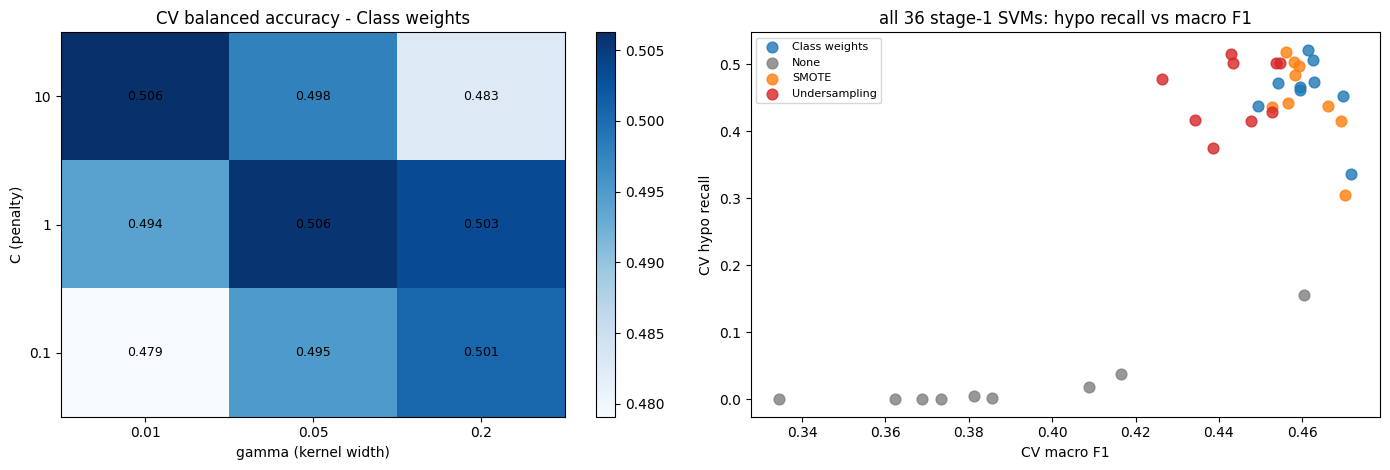

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

# (a) C x gamma heat map of CV balanced accuracy for the chosen imbalance strategy
grid_vals = (cv_all[cv_all.imbalance == chosen.imbalance]
             .pivot(index="C", columns="gamma", values="mean_test_balanced_acc").sort_index(ascending=False))
im = axes[0].imshow(grid_vals.values, cmap="Blues", aspect="auto")
axes[0].set_xticks(range(grid_vals.shape[1])); axes[0].set_xticklabels([f"{g:g}" for g in grid_vals.columns])
axes[0].set_yticks(range(grid_vals.shape[0])); axes[0].set_yticklabels([f"{c:g}" for c in grid_vals.index])
for i in range(grid_vals.shape[0]):
    for j in range(grid_vals.shape[1]):
        axes[0].text(j, i, f"{grid_vals.values[i, j]:.3f}", ha="center", va="center", fontsize=9)
axes[0].set_xlabel("gamma (kernel width)"); axes[0].set_ylabel("C (penalty)")
axes[0].set_title(f"CV balanced accuracy - {chosen.imbalance}")
fig.colorbar(im, ax=axes[0])

# (b) hypo-recall vs macro-F1 for every stage-1 SVM - the trade-off the imbalance strategies create
colors = {"None": "tab:gray", "Class weights": "tab:blue", "SMOTE": "tab:orange", "Undersampling": "tab:red"}
for name, grp in cv_all.groupby("imbalance"):
    axes[1].scatter(grp.mean_test_macro_f1, grp.mean_test_hypo_recall, color=colors[name], s=60, alpha=0.8, label=name)
axes[1].set_xlabel("CV macro F1"); axes[1].set_ylabel("CV hypo recall")
axes[1].set_title(f"all {len(cv_all)} stage-1 SVMs: hypo recall vs macro F1"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 7. preprocessing varieties at the previous stageoptimum



In [11]:
variants = {
    "original (scaled)":     {"features": FEATURE_OPTIONS["original"]},
    "pca (scaled)":          {"features": FEATURE_OPTIONS["pca"]},
    "all (scaled)":          {"features": FEATURE_OPTIONS["all"]},
    "original, no scaling":  {"features": FEATURE_OPTIONS["original"], "scaler": "passthrough", "clf__gamma": "scale"},
}
stage2 = {}
for name, override in variants.items():
    m = clone(pipe).set_params(**{**chosen_params, **override})
    stage2[name] = cross_validate(m, train[FEATURES], y_train, cv=cv, scoring=scoring, return_train_score=True, n_jobs=-1)

stage2_table = pd.DataFrame({
    name: {"CV balanced acc": r["test_balanced_acc"].mean(), "± std": r["test_balanced_acc"].std(),
           "CV hypo recall": r["test_hypo_recall"].mean(), "CV ROC AUC": r["test_roc_auc_ovr"].mean(),
           "train balanced acc": r["train_balanced_acc"].mean(),
           "train - CV gap": r["train_balanced_acc"].mean() - r["test_balanced_acc"].mean()}
    for name, r in stage2.items()}).T
print(stage2_table.round(3).to_string())

# one-standard-error rule across the three scaled feature sets
SCALED = ["original (scaled)", "pca (scaled)", "all (scaled)"]
FS_RANK = {"original (scaled)": 0, "pca (scaled)": 1, "all (scaled)": 2}
s2_mean = {n: stage2[n]["test_balanced_acc"].mean() for n in SCALED}
best_name = max(s2_mean, key=s2_mean.get)
s2_threshold = s2_mean[best_name] - stage2[best_name]["test_balanced_acc"].std() / np.sqrt(N_FOLDS)
s2_tied = [n for n in SCALED if s2_mean[n] >= s2_threshold]
final_variant = min(s2_tied, key=lambda n: FS_RANK[n])
print(f"\nBest feature set: {best_name} ({s2_mean[best_name]:.4f}); one-SE threshold {s2_threshold:.4f}; tied: {s2_tied}")
print("Chosen feature set (first by preference):", final_variant)

final_params = {**chosen_params, **variants[final_variant]}
final_feature_set = final_variant.split()[0]
final_cv = {m: stage2[final_variant][f"test_{m}"].mean() for m in scoring}
final_cv_train = {m: stage2[final_variant][f"train_{m}"].mean() for m in scoring}
final_cv_std = stage2[final_variant]["test_balanced_acc"].std()

                      CV balanced acc  ± std  CV hypo recall  CV ROC AUC  train balanced acc  train - CV gap
original (scaled)               0.506  0.006           0.507       0.678               0.573           0.067
pca (scaled)                    0.500  0.006           0.508       0.673               0.552           0.052
all (scaled)                    0.502  0.012           0.493       0.676               0.611           0.109
original, no scaling            0.496  0.013           0.502       0.669               0.511           0.016

Best feature set: original (scaled) (0.5057); one-SE threshold 0.5030; tied: ['original (scaled)']
Chosen feature set (first by preference): original (scaled)


## 8. Final model — refit on the full training set, evaluated once on the test set
The chosen configuration is rebuilt from its parameters, refit on all training rows, and evaluated on the test set.

Final model: original features, Class weights, C=1, gamma=0.05

               precision    recall  f1-score   support

Hyperglycemic      0.508     0.540     0.523       960
 Hypoglycemic      0.216     0.523     0.305       308
       Normal      0.713     0.458     0.558      1391

     accuracy                          0.495      2659
    macro avg      0.479     0.507     0.462      2659
 weighted avg      0.582     0.495     0.516      2659



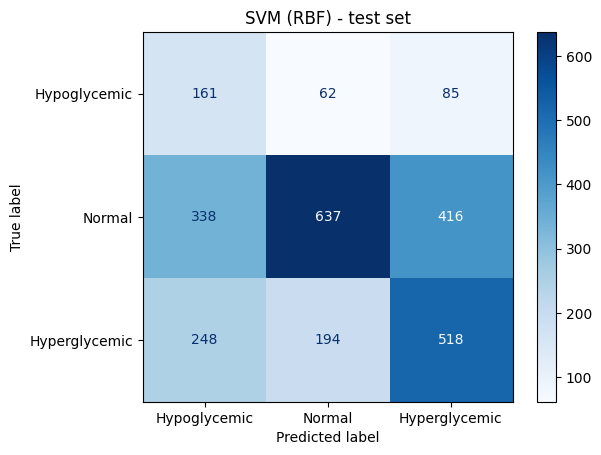

In [12]:
final_model = clone(pipe).set_params(**final_params).fit(train[FEATURES], y_train)
svc = final_model.named_steps["clf"]
FINAL_DESC = f"{final_feature_set} features, {chosen.imbalance}, C={chosen.C:g}, gamma={chosen.gamma:g}"
print("Final model:", FINAL_DESC)

y_pred = final_model.predict(test[FEATURES])
print("\n" + classification_report(y_test, y_pred, digits=3))

LABELS = ["Hypoglycemic", "Normal", "Hyperglycemic"]
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred, labels=LABELS), display_labels=LABELS).plot(cmap="Blues")
plt.title("SVM (RBF) - test set"); plt.show()

In [13]:
final_row = {"model": "SVM RBF (tuned, chosen)", **test_metrics(y_test, y_pred)}

# Untuned SVM: scikit-learn defaults (C=1, gamma="scale"), raw features, no imbalance handling
default_svc = SVC(cache_size=1000).fit(train[FEATURES], y_train)
default_row = {"model": "SVM RBF (untuned defaults)", **test_metrics(y_test, default_svc.predict(test[FEATURES]))}

SAVED = [("Random Forest (Model 3, tuned)", "model_results_random_forest.csv"),
         ("Decision Tree (Model 2, tuned)", "model_results_decision_tree.csv"),
         ("Logistic Regression (Model 1, tuned)", "model_results_logistic_regression.csv")]
rows = [default_row, final_row]
for label, path in SAVED:
    try:   # saved by the Model 1-3 notebooks: same features, same protocol, same test set
        saved = pd.read_csv(f"../results/outputs/{path}").iloc[0]
        rows.append({"model": label, **{m: saved[m] for m in ["balanced_acc", "hypo_recall", "hypo_precision", "hypo_f2", "accuracy", "macro_f1"]}})
    except FileNotFoundError:
        print(f"({path} not found - run that notebook to add its row to this table.)")

comparison = pd.DataFrame(rows)
print(comparison[["model", "balanced_acc", "hypo_recall", "hypo_precision", "hypo_f2", "accuracy", "macro_f1"]]
      .round(3).to_string(index=False))

                               model  balanced_acc  hypo_recall  hypo_precision  hypo_f2  accuracy  macro_f1
          SVM RBF (untuned defaults)         0.392        0.000           0.000    0.000     0.566     0.360
             SVM RBF (tuned, chosen)         0.507        0.523           0.216    0.407     0.495     0.462
      Random Forest (Model 3, tuned)         0.503        0.416           0.234    0.360     0.521     0.475
      Decision Tree (Model 2, tuned)         0.485        0.565           0.180    0.396     0.449     0.428
Logistic Regression (Model 1, tuned)         0.478        0.519           0.182    0.379     0.461     0.433


In [14]:
# What the hypo precision means in practice on the test set
n_alarms = int((y_pred == HYPO).sum())
n_true = int(((y_pred == HYPO) & (y_test == HYPO)).sum())
base_rate = (y_test == HYPO).mean()
alarm = {
    "hypo alarms raised":             n_alarms,
    "share of all readings flagged":  f"{n_alarms / len(y_test):.1%}",
    "real hypo events caught":        f"{n_true} of {int((y_test == HYPO).sum())}",
    "false alarms per real hypo":     f"{(n_alarms - n_true) / max(n_true, 1):.1f}",
    "precision vs base rate (lift)":  f"{(n_true / max(n_alarms, 1)) / base_rate:.2f}x",
}
print(pd.Series(alarm, name="value").to_frame().to_string())

                                    value
hypo alarms raised                    747
share of all readings flagged       28.1%
real hypo events caught        161 of 308
false alarms per real hypo            3.6
precision vs base rate (lift)       1.86x


### Comparing operating points — hypo recall at the same share of flagged readings
Hypo recall depends on how many readings a model chooses to flag, so a model that flags fewer readings can show lower
recall even when it ranks readings better. To compare like with like, the SVM's hypo decision scores are ranked and the
top share of readings is flagged, matching the share flagged by each earlier model at its own default rule. (The test
labels are used only to measure recall at flag rates fixed by the other models; nothing is tuned on the test set.)

In [15]:
classes = list(svc.classes_)
test_scores_svm = final_model.decision_function(test[FEATURES])
s_hypo = test_scores_svm[:, classes.index(HYPO)]
is_hypo = (y_test == HYPO).values

def svm_recall_at(share):
    k = int(round(share * len(y_test)))
    return is_hypo[np.argsort(-s_hypo)[:k]].sum() / is_hypo.sum()

rows = [{"compared with": "SVM itself (sanity check)", "share flagged": n_alarms / len(y_test),
         "that model's hypo recall": final_row["hypo_recall"],
         "SVM hypo recall at that share": svm_recall_at(n_alarms / len(y_test))}]
for label, path in SAVED:
    try:
        saved = pd.read_csv(f"../results/outputs/{path}").iloc[0]
        rows.append({"compared with": label, "share flagged": saved["test_flagged_share"],
                     "that model's hypo recall": saved["hypo_recall"],
                     "SVM hypo recall at that share": svm_recall_at(saved["test_flagged_share"])})
    except (FileNotFoundError, KeyError):
        print(f"({path} not found or lacks test_flagged_share - re-run that notebook to add its row.)")
matched = pd.DataFrame(rows)
print(matched.round(3).to_string(index=False))

                       compared with  share flagged  that model's hypo recall  SVM hypo recall at that share
           SVM itself (sanity check)          0.281                     0.523                          0.523
      Random Forest (Model 3, tuned)          0.205                     0.416                          0.390
      Decision Tree (Model 2, tuned)          0.364                     0.565                          0.630
Logistic Regression (Model 1, tuned)          0.330                     0.519                          0.597


### ROC AUC — ranking quality, independent of the threshold
The AUC is computed from the SVM's decision scores (one-vs-rest), as explained in Section 3. Each curve is one class
against the other two.

Test ROC AUC - Hypoglycemic vs rest : 0.676
Test ROC AUC - macro one-vs-rest    : 0.672


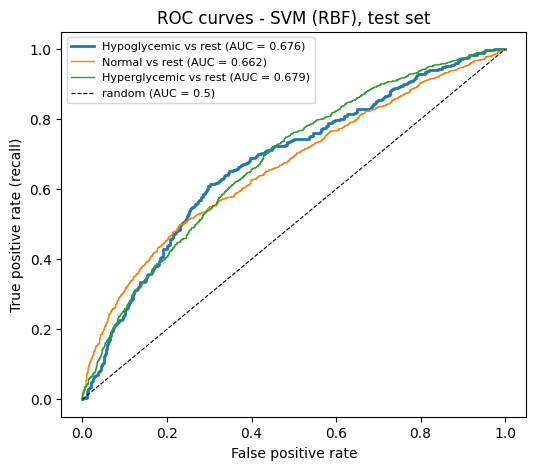

In [16]:
hypo_auc  = roc_auc_score((y_test == HYPO).astype(int), test_scores_svm[:, classes.index(HYPO)])
macro_auc = macro_auc_from_scores(final_model, test[FEATURES], y_test)
print(f"Test ROC AUC - Hypoglycemic vs rest : {hypo_auc:.3f}")
print(f"Test ROC AUC - macro one-vs-rest    : {macro_auc:.3f}")

plt.figure(figsize=(6, 5))
for c in LABELS:
    fpr, tpr, _ = roc_curve((y_test == c).astype(int), test_scores_svm[:, classes.index(c)])
    auc_c = roc_auc_score((y_test == c).astype(int), test_scores_svm[:, classes.index(c)])
    plt.plot(fpr, tpr, label=f"{c} vs rest (AUC = {auc_c:.3f})", lw=2 if c == HYPO else 1)
plt.plot([0, 1], [0, 1], "k--", lw=0.8, label="random (AUC = 0.5)")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate (recall)")
plt.title("ROC curves - SVM (RBF), test set"); plt.legend(fontsize=8); plt.show()

### Choosing the hypo alarm threshold on training data
The default rule (predict the class with the highest probability or score) is not tuned for catching hypo events. Here the
alarm threshold is chosen from **out-of-fold** hypo scores on the **training set only** — the test set plays no part in
choosing it — for three recall targets, and each resulting rule is applied to the test set once. Which recall level is
acceptable is a clinical decision; the targets only show the trade-off between caught hypo events and false alarms.

In [17]:
score_method = "predict_proba" if hasattr(final_model, "predict_proba") else "decision_function"
hypo_col = list(final_model.classes_).index(HYPO)
oof_scores = cross_val_predict(clone(final_model), train[FEATURES], y_train, cv=cv, method=score_method)[:, hypo_col]
test_hypo_scores = getattr(final_model, score_method)(test[FEATURES])[:, hypo_col]
oof_is_hypo = (y_train == HYPO).values
test_is_hypo = (y_test == HYPO).values

default_flag = (y_pred == HYPO)
rows = [{"rule": "default (highest score wins)", "threshold": np.nan,
         "test hypo recall": test_is_hypo[default_flag].sum() / test_is_hypo.sum(),
         "test hypo precision": test_is_hypo[default_flag].sum() / max(default_flag.sum(), 1),
         "test share flagged": default_flag.mean()}]
order = np.argsort(-oof_scores)
cum_recall = np.cumsum(oof_is_hypo[order]) / oof_is_hypo.sum()
for target in [0.5, 0.6, 0.7]:
    tau = oof_scores[order][np.searchsorted(cum_recall, target)]
    flag = test_hypo_scores >= tau
    rows.append({"rule": f"threshold for out-of-fold recall {target}", "threshold": tau,
                 "test hypo recall": test_is_hypo[flag].sum() / test_is_hypo.sum(),
                 "test hypo precision": test_is_hypo[flag].sum() / max(flag.sum(), 1),
                 "test share flagged": flag.mean()})
threshold_table = pd.DataFrame(rows)
print(threshold_table.round(3).to_string(index=False))
threshold_table.assign(model=final_row["model"]).to_csv(
    "../results/outputs/threshold_analysis_" + str(final_row["model"]).split()[0].lower() + ".csv", index=False)

                                rule  threshold  test hypo recall  test hypo precision  test share flagged
        default (highest score wins)        NaN             0.523                0.216               0.281
threshold for out-of-fold recall 0.5      2.084             0.513                0.217               0.273
threshold for out-of-fold recall 0.6      1.082             0.614                0.205               0.346
threshold for out-of-fold recall 0.7      0.928             0.705                0.178               0.458


## 9. Inside the SVM — support vectors
An SVM has no coefficients or rules to read. What it does expose is its **support vectors**: the training rows that
define the decision boundary. A model that separates the classes cleanly needs only a few. When the classes overlap
heavily — as they do here, with all models scoring only modestly above chance — nearly every row ends up on or inside
the margin and becomes a support vector. That makes the boundary depend on almost the whole training set and makes
prediction slow. The share on its own cannot tell weak signal from overfitting — a model that has memorised its
training data (a very large `gamma`) also makes every row a support vector, as the table in Section 10 shows — so it
has to be read together with the train-versus-validation gap there.

In [18]:
sampler = final_model.named_steps["sampler"]
if isinstance(sampler, str):
    n_fit_rows = len(train)
else:
    n_fit_rows = len(sampler.fit_resample(final_model[:2].transform(train[FEATURES]), y_train)[1])
per_class = pd.Series(svc.n_support_, index=svc.classes_, name="support vectors")
print(per_class.to_string())
print(f"\nTotal support vectors: {svc.n_support_.sum()} of {n_fit_rows} rows the SVM was fit on "
      f"({svc.n_support_.sum() / n_fit_rows:.1%})")

Hyperglycemic    3324
Hypoglycemic     1105
Normal           5111

Total support vectors: 9540 of 10635 rows the SVM was fit on (89.7%)


## 10. Overfitting check — training vs cross-validation vs test
For an SVM the overfitting controls are `C` and, above all, `gamma`. Three scores are compared for the chosen
configuration:
- **Train (in-fold):** average score on the training folds during cross-validation (data the model was fit on).
- **CV (validation):** average score on the held-out folds.
- **Test:** the final model on the test set.

The same comparison is made for the **untuned** SVM (scikit-learn defaults on raw features), and a **gamma
experiment** shows how the gap opens as `gamma` grows and the boundary starts to memorise individual readings.

In [19]:
fit_rows = ["balanced_acc", "hypo_recall", "macro_f1", "roc_auc_ovr"]
test_scores = {**test_metrics(y_test, y_pred), "roc_auc_ovr": macro_auc}
overfit = pd.DataFrame({
    "Train (in-fold)":  {m: final_cv_train[m] for m in fit_rows},
    "CV (validation)":  {m: final_cv[m] for m in fit_rows},
    "Test":             {m: test_scores[m] for m in fit_rows},
})
overfit["train - CV gap"] = overfit["Train (in-fold)"] - overfit["CV (validation)"]
print("Chosen (tuned) SVM:")
print(overfit.round(3).to_string())

# Untuned SVM: same folds, same scorers
u = cross_validate(clone(default_svc), train[FEATURES], y_train, cv=cv, scoring=scoring, return_train_score=True, n_jobs=-1)
default_test = {**test_metrics(y_test, default_svc.predict(test[FEATURES])),
                "roc_auc_ovr": macro_auc_from_scores(default_svc, test[FEATURES], y_test)}
overfit_default = pd.DataFrame({
    "Train (in-fold)":  {m: u[f"train_{m}"].mean() for m in fit_rows},
    "CV (validation)":  {m: u[f"test_{m}"].mean() for m in fit_rows},
    "Test":             {m: default_test[m] for m in fit_rows},
})
overfit_default["train - CV gap"] = overfit_default["Train (in-fold)"] - overfit_default["CV (validation)"]
print("\nUntuned SVM (defaults, raw features):")
print(overfit_default.round(3).to_string())

Chosen (tuned) SVM:
              Train (in-fold)  CV (validation)   Test  train - CV gap
balanced_acc            0.573            0.506  0.507           0.067
hypo_recall             0.637            0.507  0.523           0.131
macro_f1                0.514            0.463  0.462           0.051
roc_auc_ovr             0.742            0.678  0.672           0.064

Untuned SVM (defaults, raw features):
              Train (in-fold)  CV (validation)   Test  train - CV gap
balanced_acc            0.405            0.397  0.392           0.008
hypo_recall             0.000            0.000  0.000           0.000
macro_f1                0.376            0.367  0.360           0.009
roc_auc_ovr             0.692            0.658  0.655           0.034


 gamma  train  validation  validation std  train - validation gap
  0.05 0.5732      0.5057          0.0061                  0.0675
  0.50 0.8244      0.4928          0.0057                  0.3316
  5.00 0.9918      0.4605          0.0096                  0.5313


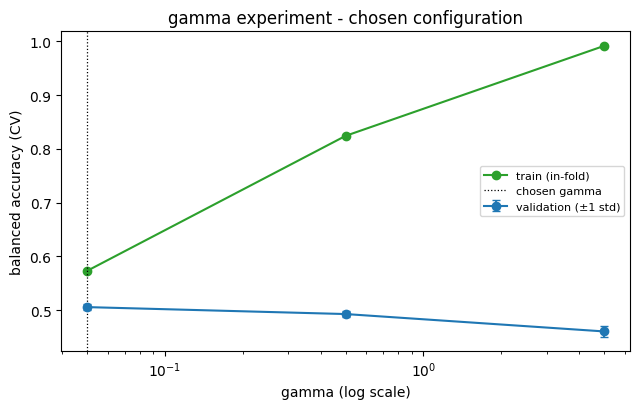

In [20]:
# gamma experiment: the chosen configuration with a much wider kernel range (train vs validation balanced accuracy)
GAMMA_SWEEP = sorted({float(chosen.gamma), 0.5, 5.0})
rows = []
for g in GAMMA_SWEEP:
    m = clone(final_model).set_params(clf__gamma=g)
    r = cross_validate(m, train[FEATURES], y_train, cv=cv, scoring="balanced_accuracy", return_train_score=True, n_jobs=-1)
    rows.append({"gamma": g, "train": r["train_score"].mean(), "validation": r["test_score"].mean(),
                 "validation std": r["test_score"].std()})
gamma_curve = pd.DataFrame(rows)
gamma_curve["train - validation gap"] = gamma_curve["train"] - gamma_curve["validation"]
print(gamma_curve.round(4).to_string(index=False))

plt.figure(figsize=(6.5, 4.2))
plt.plot(gamma_curve.gamma, gamma_curve.train, marker="o", color="tab:green", label="train (in-fold)")
plt.errorbar(gamma_curve.gamma, gamma_curve.validation, yerr=gamma_curve["validation std"], marker="o",
             color="tab:blue", capsize=3, label="validation (±1 std)")
plt.axvline(chosen.gamma, color="black", ls=":", lw=0.9, label="chosen gamma")
plt.xscale("log"); plt.xlabel("gamma (log scale)"); plt.ylabel("balanced accuracy (CV)")
plt.title("gamma experiment - chosen configuration"); plt.legend(fontsize=8); plt.tight_layout(); plt.show()

### Support vectors at each gamma
A memorising model makes every training row a support vector, so the share of support vectors alone cannot separate
"weak signal" from "overfitting". Fitting the chosen configuration on all training rows at each `gamma` shows both
numbers side by side: the support-vector share, and the accuracy on the training rows themselves.

In [21]:
sv_rows = []
for g in GAMMA_SWEEP:
    m = clone(final_model).set_params(clf__gamma=g).fit(train[FEATURES], y_train)
    sv_rows.append({"gamma": g,
                    "support vector share": m.named_steps["clf"].n_support_.sum() / n_fit_rows,
                    "balanced acc on the training rows": balanced_accuracy_score(y_train, m.predict(train[FEATURES]))})
print(pd.DataFrame(sv_rows).round(3).to_string(index=False))

 gamma  support vector share  balanced acc on the training rows
  0.05                 0.897                              0.566
  0.50                 0.916                              0.815
  5.00                 0.979                              0.990


## 11. Validation checks — does the row-wise split flatter the scores?


In [22]:
# (a) Time-ordered: each patient's first 80% of readings train, last 20% validate
ordered = train.assign(ts=pd.to_datetime(train["timestamp"])).sort_values(["patient_id", "ts", "reading_index"])
position = ordered.groupby("patient_id").cumcount()
n_readings = ordered.groupby("patient_id")["patient_id"].transform("size")
is_late = position >= np.floor(n_readings * 0.8)
early, late = ordered[~is_late], ordered[is_late]
print(f"Time-ordered split: {len(early)} earlier readings train / {len(late)} later readings validate "
      f"({late.patient_id.nunique()} patients in both)")
print(pd.DataFrame({"earlier 80%": early[TARGET].value_counts(normalize=True),
                    "later 20%":   late[TARGET].value_counts(normalize=True)}).round(3), "\n")

time_model = clone(final_model).fit(early[FEATURES], early[TARGET])
scorers = {m: (get_scorer(v) if isinstance(v, str) else v) for m, v in scoring.items()}
time_scores = {m: scorers[m](time_model, late[FEATURES], late[TARGET]) for m in scoring}

# (b) Unseen-patient generalisation check: GroupKFold, validation patients never seen in training
group_cv = cross_validate(clone(final_model), train[FEATURES], y_train, groups=groups_train,
                          cv=GroupKFold(n_splits=5), scoring=scoring, n_jobs=-1)

check = pd.DataFrame({
    "Row-wise CV (used for tuning)":     final_cv,
    "Time-ordered (monitored patients)": time_scores,
    "GroupKFold (unseen patients)":      {m: group_cv[f"test_{m}"].mean() for m in scoring},
})
check["time-ordered - row-wise"] = check["Time-ordered (monitored patients)"] - check["Row-wise CV (used for tuning)"]
check["unseen patients - row-wise"] = check["GroupKFold (unseen patients)"] - check["Row-wise CV (used for tuning)"]
print(check.round(3).to_string())

Time-ordered split: 8477 earlier readings train / 2158 later readings validate (70 patients in both)
                 earlier 80%  later 20%
next_risk_class                        
Normal                 0.519      0.540
Hyperglycemic          0.363      0.351
Hypoglycemic           0.117      0.109 

                Row-wise CV (used for tuning)  Time-ordered (monitored patients)  GroupKFold (unseen patients)  time-ordered - row-wise  unseen patients - row-wise
balanced_acc                            0.506                              0.547                         0.472                    0.042                      -0.033
hypo_f2                                 0.394                              0.443                         0.365                    0.049                      -0.030
hypo_recall                             0.507                              0.591                         0.483                    0.085                      -0.024
hypo_precision                          0

### Which features does the SVM depend on? — permutation importance
An SVM has no built-in feature importance, so each feature is shuffled in turn and the drop in balanced accuracy is
measured. The SVM trained on each patient's **earlier** readings is scored on their **later** readings, so this shows
what it depends on for predicting the future. A drop near zero means the feature is not needed for that prediction.
The estimate is repeated 5 times per feature, and the standard deviation shows how noisy it is. Only training-set rows
are used, never the test set. Highly correlated features share credit, so shuffling one at a time understates each.

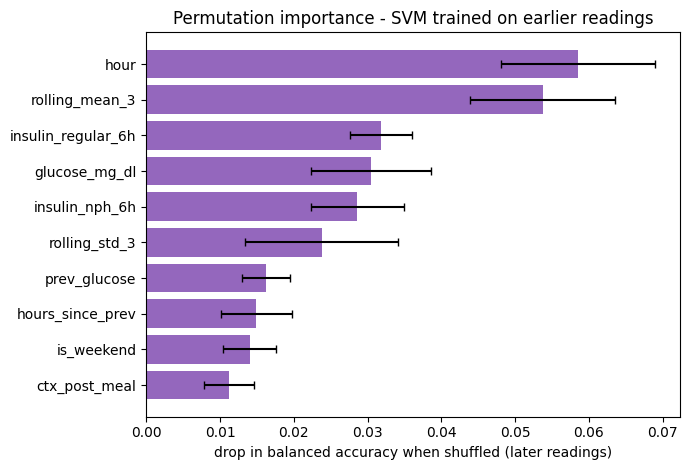

                    permutation drop     std
hour                          0.0585  0.0104
rolling_mean_3                0.0537  0.0098
insulin_regular_6h            0.0318  0.0042
glucose_mg_dl                 0.0305  0.0082
insulin_nph_6h                0.0286  0.0063
rolling_std_3                 0.0238  0.0104
prev_glucose                  0.0162  0.0033
hours_since_prev              0.0149  0.0048
is_weekend                    0.0140  0.0036
ctx_post_meal                 0.0112  0.0034


In [23]:
perm = permutation_importance(time_model, late[FEATURES], late[TARGET], scoring="balanced_accuracy",
                              n_repeats=5, random_state=RANDOM_STATE, n_jobs=1)
perm_imp = pd.Series(perm.importances_mean, index=FEATURES).sort_values(ascending=False)
perm_std = pd.Series(perm.importances_std, index=FEATURES)[perm_imp.index]
top_perm = perm_imp.head(10)

fig, ax = plt.subplots(figsize=(7, 4.8))
ax.barh(range(len(top_perm))[::-1], top_perm.values, xerr=perm_std[top_perm.index].values, color="tab:purple", capsize=3)
ax.set_yticks(range(len(top_perm))[::-1]); ax.set_yticklabels(top_perm.index)
ax.set_xlabel("drop in balanced accuracy when shuffled (later readings)")
ax.set_title("Permutation importance - SVM trained on earlier readings")
plt.tight_layout(); plt.show()
print(pd.DataFrame({"permutation drop": top_perm.round(4), "std": perm_std[top_perm.index].round(4)}).to_string())

**`reading_index` is excluded from the features.** It is the reading's position in that patient's record (scaled), not a
physiological measurement. Pooled over patients, the hypo share can look as if it falls late in a record, but the two
tables below separate that pattern into its parts: **within** a patient's own record the hypo share barely moves, while
**between** patients it differs clearly, and the highest values of `reading_index` occur only in the patients with the
longest records. The feature therefore partly identifies *which patient* a reading comes from. In time-ordered validation
a patient's later readings receive larger `reading_index` values than any of their earlier ones, so a model that has
learned "large index = lower hypo risk" from the between-patient pattern is most consistent with under-predicting hypo on
future readings. In a separate audit on the training set, removing the feature raised time-ordered hypo recall at each of
three time cut points for each of the five models trained before KNN (15 of 15 comparisons), so it is excluded for all
six models. The sensitivity check at the end of Section 11 adds it back to this model.

In [24]:
ordered_ev = train.assign(ts=pd.to_datetime(train["timestamp"])).sort_values(["patient_id", "ts", "reading_index"])
n_ev = ordered_ev.groupby("patient_id")["patient_id"].transform("size")
ordered_ev["own_position"] = ordered_ev.groupby("patient_id").cumcount() / n_ev
ordered_ev["hypo_next"] = (ordered_ev[TARGET] == HYPO).astype(int)
ordered_ev["own_fifth"] = pd.cut(ordered_ev["own_position"], [0, 0.2, 0.4, 0.6, 0.8, 1.0], right=False,
                                 labels=["1st", "2nd", "3rd", "4th", "5th"])
print("WITHIN patients: share of readings whose NEXT reading is hypoglycemic, by fifth of that patient's own record")
print(ordered_ev.groupby("own_fifth", observed=True)["hypo_next"].mean().round(3).to_string())

per_patient = ordered_ev.groupby("patient_id").agg(readings=("hypo_next", "size"), hypo_share=("hypo_next", "mean"),
                                                   highest_index=("reading_index", "max"))
per_patient["record length"] = pd.qcut(per_patient["readings"], 3, labels=["short", "medium", "long"])
print("\nBETWEEN patients: by length of the patient's record")
print(per_patient.groupby("record length", observed=True).agg(
    patients=("readings", "size"), mean_readings=("readings", "mean"), hypo_share=("hypo_share", "mean"),
    mean_highest_reading_index=("highest_index", "mean")).round(3).to_string())

WITHIN patients: share of readings whose NEXT reading is hypoglycemic, by fifth of that patient's own record
own_fifth
1st    0.125
2nd    0.122
3rd    0.123
4th    0.102
5th    0.108

BETWEEN patients: by length of the patient's record
               patients  mean_readings  hypo_share  mean_highest_reading_index
record length                                                                 
short                24         66.833       0.179                      -0.089
medium               23         98.000       0.128                       0.104
long                 23        294.652       0.121                       1.427


## 12. Conclusion, limitations and improvements
*(Interpretation of the generated summary above; every number quoted there comes from this run.)*

**What mattered:**
1. **Handling the imbalance mattered; class weights and SMOTE tie.** Without it the best SVM catches only about 16% of hypo events (recall 0.155) and balanced accuracy is 0.455. With class weights (0.506), SMOTE (0.503) or undersampling (0.495) it is higher; class weights and SMOTE cannot be told apart, and undersampling is slightly lower. The untuned default SVM (raw features, no imbalance handling) never predicts hypo at all (recall 0.000, balanced accuracy 0.392).
2. **`gamma` and `C` control the overfitting, and the best settings are smooth.** In the gamma experiment, training balanced accuracy climbs from 0.573 to 0.992 as `gamma` grows from 0.05 to 5 while validation falls from 0.506 to 0.460: at a large `gamma` the boundary memorises individual readings. The two competitive settings (`C` = 10 with `gamma` = 0.01, and `C` = 1 with `gamma` = 0.05) are both on the smooth side.
3. **Scaling helped only a little.** The scaled SVM scores 0.506 and the unscaled one 0.496, a difference of about one fold-to-fold standard deviation. The collapse of the untuned default comes from the missing imbalance handling, not from the missing scaling.
4. **The original features are enough.** Original 0.506, PCA 0.500 and all features 0.502 differ by less than the noise; `gamma` was not re-tuned for the PCA sets, which limits that comparison.
5. **Most training rows become support vectors, but this SVM is not memorising.** 89.7% of the rows are support vectors, and the share alone cannot separate weak signal from memorisation (it reaches 98% at `gamma` = 5). What shows the chosen model is not memorising is its train-versus-validation gap: 0.067 at the chosen `gamma`, against 0.33 and 0.53 at larger values.
6. **Performance relative to the other models.** Balanced accuracy (0.507) is level with the Random Forest (0.503) and above the tree and the linear model. Macro ROC AUC (0.672) is above the tree (0.656) and Logistic Regression (0.652) but below the forest (0.701). At the tree's and Logistic Regression's flag rates it catches more hypo events (0.630 against 0.565, and 0.597 against 0.519), but at the forest's lower flag rate it catches slightly fewer (0.390 against 0.416). So it ranks hypo readings better than the simpler models and not as well as the forest.

**Reading the SVM:**
- An SVM has no readable rules or coefficients. Permutation importance on later readings puts time of day (`hour`, 0.058) and recent glucose (`rolling_mean_3`, 0.054) first, followed by `insulin_regular_6h`, `glucose_mg_dl` and `insulin_nph_6h`. Correlated glucose features share credit.
- **`reading_index` sensitivity (Section 11).** The evidence is mixed. Adding it back lowers the time-ordered scores (balanced accuracy 0.547 to 0.533, hypo recall 0.591 to 0.498), but it slightly raises the row-wise CV (0.506 to 0.512) and the unseen-patient balanced accuracy and hypo recall (by 0.002 and 0.010). So for this model the case for excluding it rests on the monitored-patient check; on the other checks it makes little difference, within the noise.

**Validation checks.** Time-ordered balanced accuracy is 0.547 (+0.042 against the row-wise CV) and unseen-patient balanced accuracy is 0.472 (−0.033, a larger drop than Logistic Regression's −0.020). The time-ordered figure is about 0.040 above a baseline that uses no features at all and only each patient's own earlier class frequencies (0.507; group comparison notebook).

**Limitations:**
- **Two-stage tuning and a coarse grid:** three values each of `C` and `gamma`, and the kernel width was not re-tuned for each feature set.
- **No probabilities:** the ROC AUC comes from decision scores, and the alarm thresholds in Section 8 are decision-score values, not probabilities.
- **Cost:** training is slow, and prediction is slow because 89.7% of the training rows are support vectors.
- **Alarm burden:** about 3.6 false alarms per real hypo event at the default rule, and the threshold analysis shows that reaching 70% recall means flagging about 46% of all readings, at about 4.6 false alarms per real event.
- **Weaker on unseen patients** than on already-monitored ones (−0.033).
- **Validation for the use case.** The reviewed row-wise split is kept for tuning and testing. The time-ordered figure is the one to quote for future readings of monitored patients; it comes from a single holdout, so differences of a few hundredths are noise. The GroupKFold check shows generalisation to unseen patients.
- **Leakage handled:** `daily_total_insulin` and `reading_index` are excluded, PCA is re-fit inside the pipeline, and the `*_6h` windows were verified as backward-looking in the preprocessing code (they include events logged at the same timestamp as the reading; some timestamps are conventional slot times).
- **Test-set use during development:** nothing was chosen or tuned on the test set, but its results were viewed while the notebook was developed, and the threshold analysis and the matched-flag-rate table use test labels only to evaluate rules chosen on training data or at other models' flag rates.

**Improvements:**
- Compare a linear kernel with the RBF kernel (as Lab 4 does) to show what the non-linear boundary buys.
- Re-tune `gamma` for each feature set, and use a finer or randomised search over `C` and `gamma`.
- Use the alarm threshold from Section 8 for a clinically chosen recall, and calibrate the scores (for example with Platt scaling) if probabilities are needed.